In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm

In [2]:
dat = pd.read_csv("../Processed_Data/VST.csv")
dat.head()

,GeneID,LD_ZT02,LD_ZT05,LD_ZT08,LD_ZT11,LD_ZT14,LD_ZT17,LD_ZT20,LD_ZT23,LD_ZT26,LD_ZT29,LD_ZT32,LD_ZT35,LD_ZT38,LD_ZT41,LD_ZT44,LD_ZT47
0,AT1G01010,8.554253,8.262655,8.444297,8.848163,8.294843,8.225076,8.755916,8.645262,8.778685,8.371858,8.211943,8.308967,9.016021,8.539922,8.849960,8.939105
1,AT1G01020,8.444317,8.326703,8.301096,8.438758,8.576127,8.354160,8.290645,8.412673,8.261971,8.374001,8.355511,8.274218,8.449209,8.550386,8.530969,8.289782
2,AT1G01030,7.448145,7.421349,7.110650,7.321919,6.758200,6.821116,7.474132,7.486354,8.151697,7.307972,7.555016,6.958064,7.420145,7.167180,7.421193,7.549966
3,AT1G01040,10.152389,10.286602,10.224319,9.768661,10.069034,10.013264,10.068108,9.887160,10.270266,10.138990,10.259088,10.169168,9.951947,9.939831,10.143107,10.189433
4,AT1G01050,10.617507,10.286750,10.169515,10.039364,10.167519,10.254922,10.390082,10.650028,10.574841,10.301623,10.197488,10.006225,10.107959,10.239052,10.437588,10.545576


### Detection of periodic genes

Use LombScargle (LS) to pull best_period, power, fap

Note:

FMIN = 1/48

This would only allow 1 cycle of data, which isn't very convincing but I'll only keep frequencies below 1/32, i.e. 1.5 cycles observed.
However, the FMIN is set to 1/48 to avoid the detected frequency and confidence intervals piling up at a period of 32.

FMAX = 1/6 this is the Nyquist limit.

In [3]:
# Keep all constants in one place (shared with boot_worker)
from boot_worker import FMIN, FMAX, N_BOOT, SAMPLES_PER_PEAK, time_grid, n_points

In [4]:
def ls_analysis(y, samples_per_peak=SAMPLES_PER_PEAK):
    y = y - np.mean(y)

    ls = LombScargle(time_grid, y)
    frequency, power = ls.autopower(
        minimum_frequency=FMIN,
        maximum_frequency=FMAX,
        samples_per_peak=samples_per_peak
    )
    best_idx = np.argmax(power)
    best_frequency = frequency[best_idx]
    best_period = 1 / best_frequency
    best_power = power[best_idx]
    fap = ls.false_alarm_probability(
        best_power,
        minimum_frequency=FMIN,
        maximum_frequency=FMAX)
    [offset, sin_coeff, cos_coeff] = ls.model_parameters(best_frequency)
    phase = np.arctan2(sin_coeff, cos_coeff)
    phase_hours = (phase % (2*np.pi)) / (2*np.pi) * (1/best_frequency)

    return [best_period, best_power, fap, phase_hours]

def ls_analysis_all_genes(dat, samples_per_peak):
    ls_dict = {}
    for gene in tqdm(dat["GeneID"]):
        y = dat[dat['GeneID'] == gene].drop(columns=['GeneID']).astype(float).to_numpy().squeeze()
        ls_dict[gene] = ls_analysis(y, samples_per_peak = samples_per_peak)

    ls_df = pd.DataFrame.from_dict(ls_dict, orient='index')
    ls_df = ls_df.reset_index()
    ls_df.columns = ['GeneID', "best_period", "best_power", "fap", "phase_hours"]
    
    #Multiple testing correction
    reject, pvals_corrected, alphacSidak, alphacBonf = multipletests(
        ls_df.fap,
        alpha=0.05,
        method="fdr_bh"
    )
    ls_df['qval'] = pvals_corrected
    return ls_df

Helper function for plotting

In [5]:
def plot_gene(GeneID, dat, ax):
    x = np.array(range(2, 50, 3))
    y = dat[dat['GeneID'] == GeneID].drop(columns=['GeneID']).astype(float).to_numpy().squeeze()
    ax.scatter(x, y)
    ax.set_xlabel("time_point")
    ax.set_ylabel("norm_expression")
    ax.set_title(f"{GeneID} Expression")

def plot_phase_fold(GeneID, dat, ls_df, ax):
    x = np.array(range(2, 50, 3))
    best_period = ls_df[ls_df['GeneID'] == GeneID]['best_period'].iloc[0]
    phase = (x % best_period) / best_period
    y = dat[dat['GeneID'] == GeneID].drop(columns=['GeneID']).astype(float).to_numpy().squeeze()
    
    ax.scatter(phase, y)
    ax.set_title(f"{GeneID} phase folded")
    ax.set_xlabel("Phase")
    ax.set_ylabel("Expression")

def plot_both(GeneID, dat, ls_df, master_title = None):
    fig, axes = plt.subplots(1, 2, figsize=(12,5))

    plot_gene(GeneID, dat, axes[0])
    plot_phase_fold(GeneID, dat, ls_df, axes[1])

    fig.tight_layout(rect=[0, 0, 1, 0.93])

    if master_title:
        fig.suptitle(master_title)
    plt.show()

Note: samples_per_peak controls how fine the frequency search grid is. Higher the number, the more unique frequency can be detected. Here I'm using 30 to give more variety in frequency options but below I'll extract a confidence interval for each frequency so the reporting can be more honest and not over esimate the precision of the method

In [6]:
ls_df = ls_analysis_all_genes(dat, samples_per_peak=SAMPLES_PER_PEAK)

100%|██████████| 19215/19215 [00:24<00:00, 793.53it/s]


In [7]:
housekeeping = {"AT4G05320": "UBQ10", "AT3G52590": "UBQ1", "AT3G18780": "ACT2", "AT1G13320": "PP2AA3"}
circadian = {"AT5G61380": "TOC1", "AT2G46830": "CCA1", "AT1G01060": "LHY", "AT5G24470": "PRR5"}
out_df = pd.concat([
    ls_df[ls_df.GeneID.isin(housekeeping)].assign(**{"class": "housekeeping"}),
    ls_df[ls_df.GeneID.isin(circadian)].assign(**{"class": "circadian"}),
])
out_df["Name"] = out_df.GeneID.map({**housekeeping, **circadian})
print(out_df)

          GeneID  best_period  best_power           fap  phase_hours  \
1010   AT1G13320    48.000000    0.366106  5.896750e-01    41.170576   
9419   AT3G18780    24.489796    0.754018  4.206202e-03    23.428103   
10860  AT3G52590    13.219094    0.809064  9.508548e-04    13.130800   
12071  AT4G05320    24.489796    0.565113  1.068491e-01     1.896644   
5      AT1G01060    23.632385    0.952320  2.472747e-07     1.721389   
7847   AT2G46830    23.632385    0.868132  1.064610e-04     4.002429   
16437  AT5G24470    24.053452    0.702659  1.265913e-02    11.834625   
18603  AT5G61380    24.489796    0.831682  4.518035e-04    15.224816   

           qval         class    Name  
1010   0.733943  housekeeping  PP2AA3  
9419   0.056283  housekeeping    ACT2  
10860  0.022290  housekeeping    UBQ1  
12071  0.356938  housekeeping   UBQ10  
5      0.000319     circadian     LHY  
7847   0.005950     circadian    CCA1  
16437  0.109275     circadian    PRR5  
18603  0.013935     circadian  

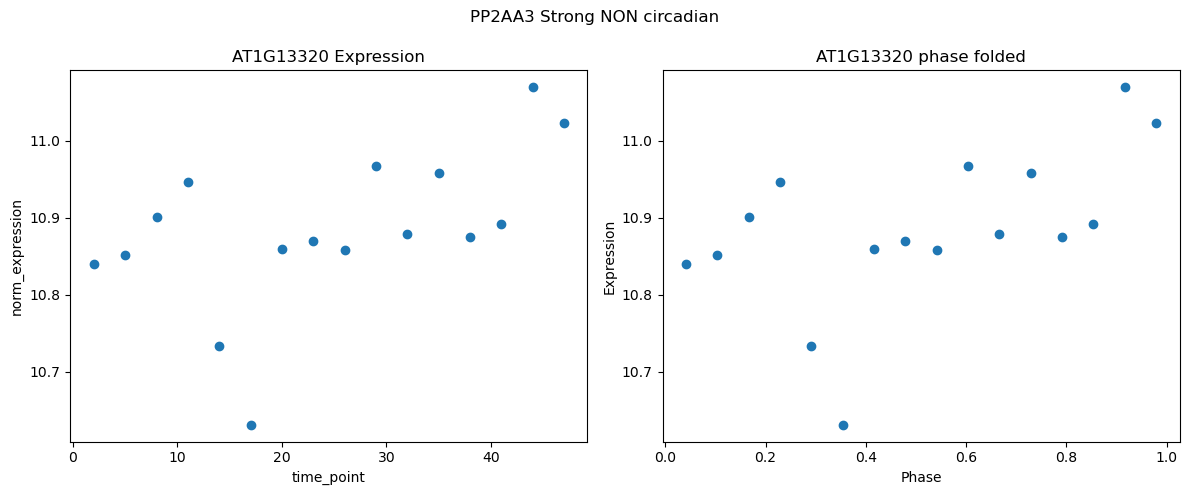

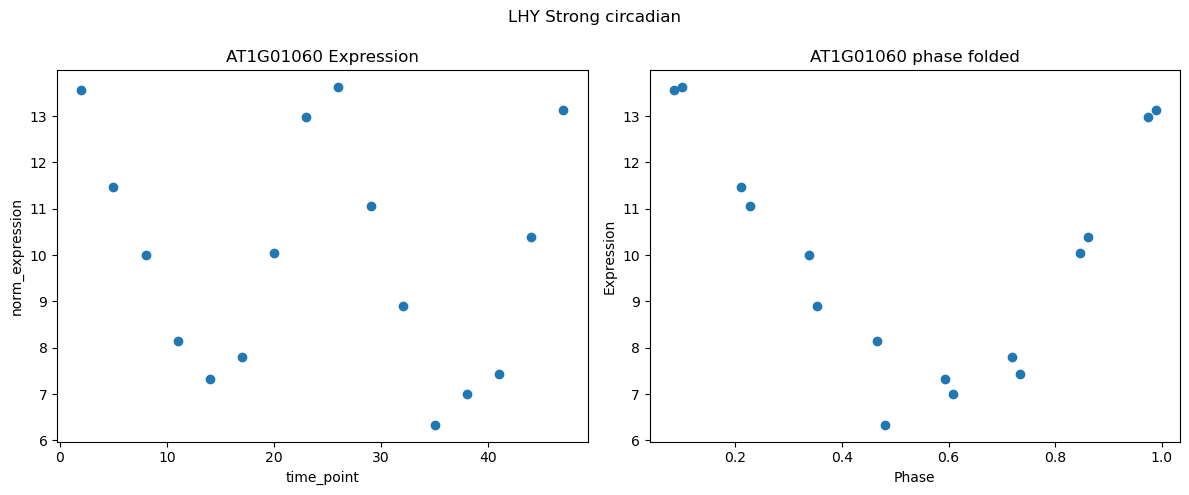

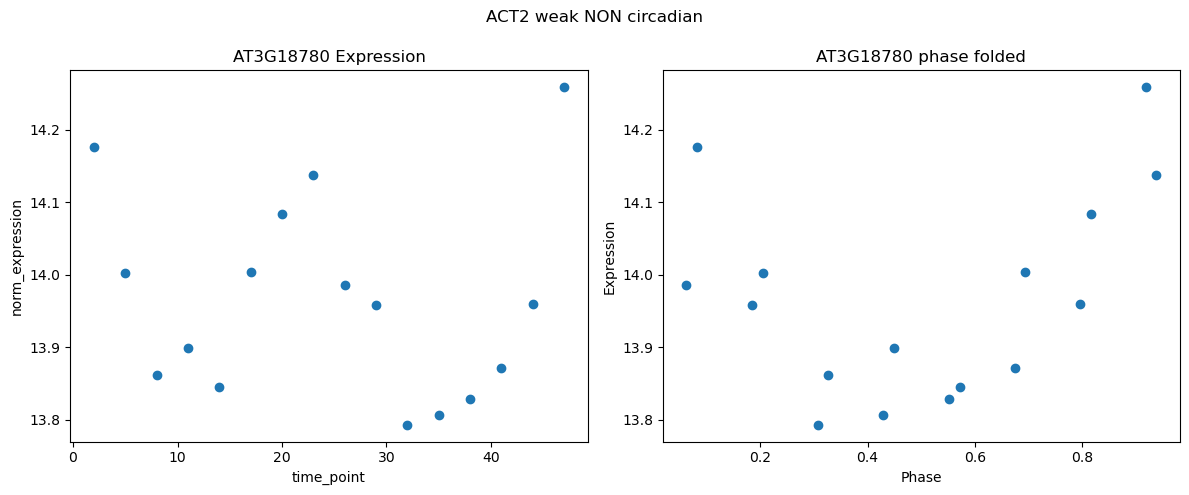

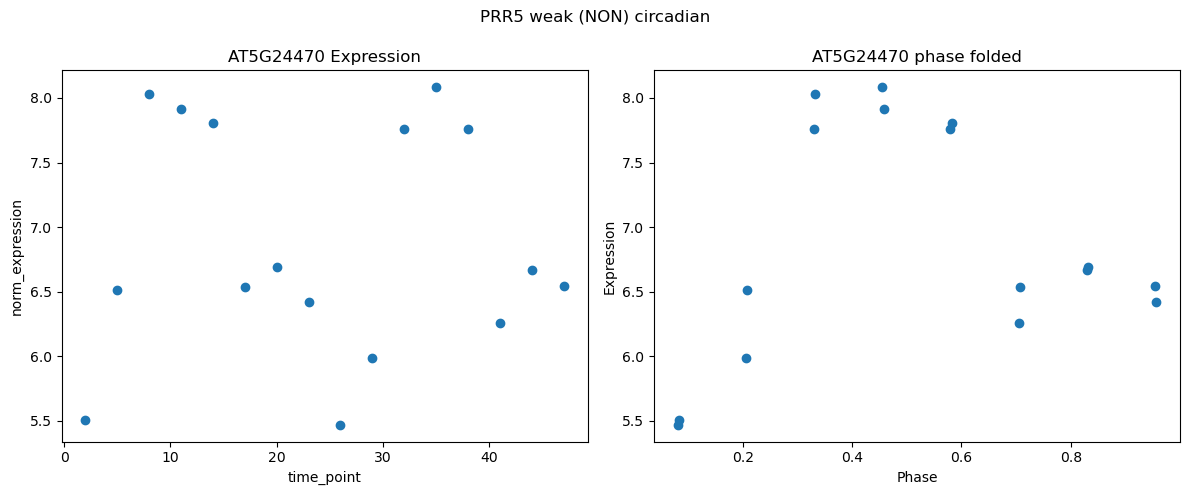

In [8]:
#%% Call Plots
plot_both("AT1G13320", dat, ls_df, "PP2AA3 Strong NON circadian")
plot_both("AT1G01060", dat, ls_df, "LHY Strong circadian")
plot_both("AT3G18780", dat, ls_df, "ACT2 weak NON circadian")
plot_both("AT5G24470", dat, ls_df, "PRR5 weak (NON) circadian")

### Check qval and peak time against known circadian genes

DOI:10.1186/gb-2013-14-6-208 has a diagram showing peak time of various circadian genes in Arabidopsis

In [9]:
circadian_genes = {
    "AT2G46830":"CCA1",
    "AT1G01060":"LHY",
    "AT3G09600":"RVE8",
    "AT2G46790":"PRR9",
    "AT5G02810":"PRR7",
    "AT5G24470":"PRR5",
    "AT5G08330":"CHE",
    "AT5G61380":"TOC1",
    "AT2G25930":"ELF3",
    "AT2G40080":"ELF4",
    "AT3G46640":"LUX",
}

circadian_df = ls_df[ls_df.GeneID.isin(circadian_genes)].copy()
circadian_df["Name"] = circadian_df.GeneID.map(circadian_genes)
circadian_df.sort_values("phase_hours")

,GeneID,best_period,best_power,fap,phase_hours,qval,Name
5,AT1G01060,23.632385,0.952320,2.472747e-07,1.721389,0.000319,LHY
8656,AT3G09600,23.632385,0.911267,1.008945e-05,2.119366,0.001657,RVE8
7847,AT2G46830,23.632385,0.868132,1.064610e-04,4.002429,0.005950,CCA1
7843,AT2G46790,24.942263,0.899880,2.070995e-05,5.581692,0.002355,PRR9
15230,AT5G08330,12.485549,0.508143,2.017884e-01,6.506736,0.485399,CHE
14779,AT5G02810,24.489796,0.923895,4.039450e-06,8.572266,0.000947,PRR7
16437,AT5G24470,24.053452,0.702659,1.265913e-02,11.834625,0.109275,PRR5
10406,AT3G46640,23.632385,0.896806,2.479342e-05,13.271505,0.002563,LUX
18603,AT5G61380,24.489796,0.831682,4.518035e-04,15.224816,0.013935,TOC1
6183,AT2G25930,25.899281,0.772121,2.689213e-03,16.929920,0.042312,ELF3


The general trend matches quite well with the paper. Only discrepency here is that two of the ten circadian genes here (CHE and PRR5) failed the qval threshold of 0.05.

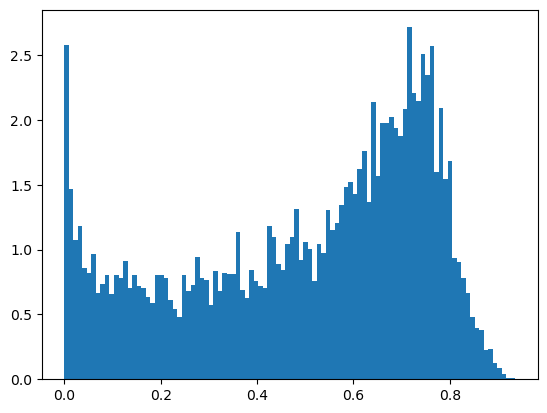

In [10]:
plt.hist(ls_df.qval, density=True, bins=100)
plt.show()

### Determining qval cut off

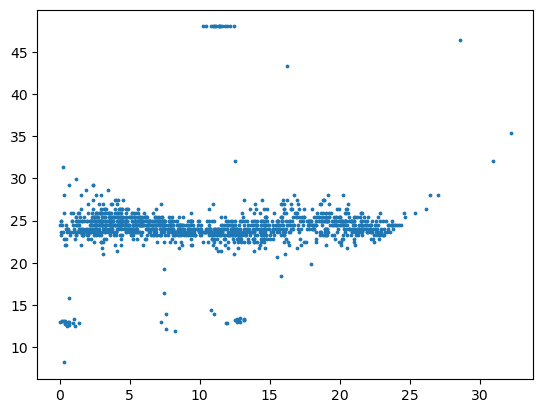

In [11]:
# Visualize with qval 0.05
ls_df_qval05 = ls_df[ls_df['qval'] <= 0.05]
plt.scatter(ls_df_qval05.phase_hours, ls_df_qval05.best_period, s=3)

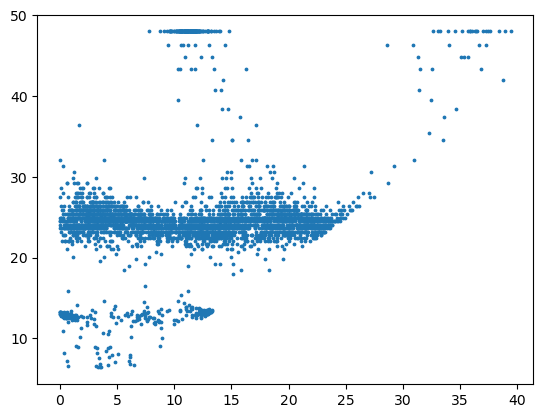

In [12]:
# Visualize with qval 0.2
ls_df_qval2 = ls_df[ls_df['qval'] <= 0.2]
plt.scatter(ls_df_qval2.phase_hours, ls_df_qval2.best_period, s=3)

I'll use qval of 0.2 as cutoff for data generation, and in the web visualization I'll highlight points with qval < 0.05 and let user use slider to adjust for themselves.

### Final Processing

In [14]:
# Select cutoff at q <= 0.2 & and best_period ≤ 32
ls_df_spp30 = ls_analysis_all_genes(dat, samples_per_peak=30) #Can skip if ran above, included here for completeness
ls_df_spp30_qval2 = ls_df[(ls_df['qval'] <= 0.2) & (ls_df['best_period'] <= 32)].copy()
oscillating_dat = dat[dat.GeneID.isin(ls_df_spp30_qval2.GeneID)].copy()
print(f"{len(ls_df_spp30_qval2)} / {len(ls_df_spp30)} genes pass qval≤0.2 and period≤32")

100%|██████████| 19215/19215 [00:24<00:00, 768.61it/s]

3286 / 19215 genes pass qval≤0.2 and period≤32


### Determine confidence of detected period using bootstrapping

The script for bootstrapping is moved to boot_worker.py for sake of parallelization. 
The function/workers outputs period_sd, period_low95, period_high95, log_period_sd.

In [15]:
import multiprocessing as mp
from boot_worker import boot_one_gene

Y = oscillating_dat.drop(columns=['GeneID']).to_numpy(float)
args = [(g, y) for (g,y) in zip(oscillating_dat.GeneID, Y)]
ctx = mp.get_context("spawn")
with ctx.Pool(processes=max(1, mp.cpu_count() - 1)) as pool:
    results = list(tqdm(pool.imap_unordered(boot_one_gene, args, chunksize=25), total = len(args)))

oscillating_conf = pd.DataFrame(results)

100%|██████████| 3286/3286 [00:26<00:00, 125.52it/s]


In [16]:
out_df = pd.merge(ls_df_spp30_qval2, oscillating_conf, how = "left", on = "GeneID", validate="one_to_one")
out_df.to_csv("../Processed_Data/ls.csv", index=False)